In [1]:
# ==============================================================================
# CELL 0: CONFIGURATION & IMPORTS
# ==============================================================================
%load_ext autoreload

import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm
from scipy.spatial import cKDTree
from scipy.interpolate import interp1d
from scipy.stats import binned_statistic
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar
from tqdm import tqdm

import fake_spectra.spectra as spectra
import fake_spectra.abstractsnapshot as absn
import fake_spectra.unitsystem as unitsystem
import fake_spectra.gas_properties as gas_properties
import fake_spectra.randspectra as randspectra

def matplotlib_default_config():
    """Returns default matplotlib configuration dictionaries."""
    font = {'family': 'serif', 'weight': 'normal', 'size': 14}
    rcnew = {
        "mathtext.fontset": "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2.0, "axes.titlesize": 20, "axes.labelsize": 18,
        "legend.fontsize": 16, 'legend.fancybox': True, 'lines.linewidth': 2.0,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 16,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 8.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 4.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 16,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 8.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 4.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

In [2]:
# ==============================================================================
# CELL 1: SETUP & HALO EXTRACTION
# ==============================================================================
base_path = '/home/STORAGE/TNG50-4'
snap_num = 25 
target_halo_id = 1700
   

def get_halo_info(base_dir, snap_number, halo_id):
    group_dir = os.path.join(base_dir, f"groups_{snap_number:03d}")
    file0 = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number:03d}.0.hdf5")
    
    with h5py.File(file0, 'r') as f:
        num_files = f['Header'].attrs['NumFiles']
        box_size = f['Header'].attrs['BoxSize']
        
    current_id_offset = 0
    for i in range(num_files):
        filepath = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number:03d}.{i}.hdf5")
        with h5py.File(filepath, 'r') as f:
            if 'Group' not in f or 'GroupMass' not in f['Group']:
                continue
            n_halos = len(f['Group/GroupMass'])
            if halo_id < current_id_offset + n_halos:
                local_index = halo_id - current_id_offset
                pos = f['Group/GroupPos'][local_index]
                vel = f['Group/GroupVel'][local_index]
                return pos, vel, box_size
            current_id_offset += n_halos
    raise ValueError(f"Halo ID {halo_id} not found.")

halo_pos, halo_vel, box_size = get_halo_info(base_path, snap_num, target_halo_id)
y_sk, z_halo = halo_pos[1], halo_pos[2]
box_size_cMpc = box_size / 1000.0
halo_x_plot = halo_pos[0] / 1000.0 

# ==============================================================================
# CELL 2: READ RAW GAS DATA ALONG SKEWER (FULL BOX)
# ==============================================================================
snap_file_0 = os.path.join(base_path, f'snapdir_{snap_num:03d}', f'snap_{snap_num:03d}.0.hdf5')

with h5py.File(snap_file_0, 'r') as f:
    if 'NumFilesPerSnapshot' in f['Header'].attrs:
        num_snap_files = f['Header'].attrs['NumFilesPerSnapshot']
    else:
        num_snap_files = f['Header'].attrs['NumFiles']
        
    hubble = f['Header'].attrs.get('HubbleParam', 0.6774)
    a_scale = f['Header'].attrs.get('Time', 1.0)
    z_sim = (1.0/a_scale) - 1.0

coords_list, rho_list, fhi_list = [], [], []

print("Fetching raw cells along the sightline across the full box...")
for i in tqdm(range(num_snap_files), desc="Reading Snapshot Chunks"):
    snap_file = os.path.join(base_path, f'snapdir_{snap_num:03d}', f'snap_{snap_num:03d}.{i}.hdf5')
    if not os.path.exists(snap_file): continue

    try:
        with h5py.File(snap_file, 'r') as f:
            if 'PartType0' not in f: continue
            
            coords = f['PartType0']['Coordinates'][:]
            masses = f['PartType0']['Masses'][:]
            rho_code = f['PartType0']['Density'][:]
            
            # Extract native neutral hydrogen fraction
            if 'NeutralHydrogenAbundance' in f['PartType0']:
                fHI_code = f['PartType0']['NeutralHydrogenAbundance'][:]
            elif 'FractionH0' in f['PartType0']:
                fHI_code = f['PartType0']['FractionH0'][:]
            else:
                fHI_code = np.ones_like(rho_code) 
            
            # Effective cell radius
            hsml = np.cbrt(masses / rho_code)

            # Perpendicular distance to the skewer (X-axis) handling PBC
            dy_sk = np.abs(coords[:, 1] - y_sk)
            dz_sk = np.abs(coords[:, 2] - z_halo)
            dy_sk = np.where(dy_sk > box_size / 2.0, box_size - dy_sk, dy_sk)
            dz_sk = np.where(dz_sk > box_size / 2.0, box_size - dz_sk, dz_sk)
            d_perp = np.sqrt(dy_sk**2 + dz_sk**2)

            mask_sk = d_perp <= hsml
            
            if np.sum(mask_sk) > 0:
                coords_list.append(coords[mask_sk])
                rho_list.append(rho_code[mask_sk])
                fhi_list.append(fHI_code[mask_sk])
    except Exception as e:
        pass

coords_all = np.concatenate(coords_list)
rho_all = np.concatenate(rho_list)
fHI_all = np.concatenate(fhi_list)

# Density conversion from code units to Physical (total n_H in cm^-3)
X_H = 0.76  
m_p = 1.67262192e-24  
density_to_cgs = (1.989e43 / (3.085678e21**3)) * (hubble**2) / (a_scale**3)

rho_phys_cgs = rho_all * density_to_cgs
nH_raw = (rho_phys_cgs * X_H) / m_p

x_plot = coords_all[:, 0] / 1000.0 # Absolute cMpc/h

# Relative wrapped coordinates for the plots and fitting later
dx_skewer = x_plot - halo_x_plot
dx_skewer_wrapped = (dx_skewer + (box_size_cMpc / 2.0)) % box_size_cMpc - (box_size_cMpc / 2.0)

# ==============================================================================
# CELL 3: CALCULATE ANALYTIC THRESHOLD (Schaye 2001 + Rahmati 2013)
# ==============================================================================
class RahmatiCorrectorMock:
    def __init__(self, redshift, fbar=0.17):
        zz = [0, 1, 2, 3, 4, 5, 6, 7, 8]
        gamma_UVB_vals = [3.99e-14, 3.03e-13, 6e-13, 5.53e-13, 4.31e-13, 3.52e-13, 2.678e-13,  1.81e-13, 9.43e-14]
        gray_opac_vals = [2.59e-18, 2.37e-18, 2.27e-18, 2.15e-18, 2.02e-18, 1.94e-18, 1.82e-18, 1.71e-18, 1.60e-18]
        self.gamma_UVB = interp1d(zz, gamma_UVB_vals, fill_value="extrapolate")(redshift)
        self.gray_opac = interp1d(zz, gray_opac_vals, fill_value="extrapolate")(redshift)
        self.f_bar = fbar

    def get_neutral_fraction(self, nH, temp=1e4):
        T4 = temp / 1e4
        G12 = self.gamma_UVB / 1e-12
        nSSh = 6.73e-3 * (self.gray_opac / 2.49e-18)**(-2./3) * T4**0.17 * G12**(2./3) * (self.f_bar / 0.17)**(-1./3)
        photUVBratio = 0.98 * (1 + (nH/nSSh)**1.64)**(-2.28) + 0.02 * (1 + nH/nSSh)**(-0.84)
        photo_rate = photUVBratio * self.gamma_UVB
        lamb = 315614.0 / temp
        alpha_A = 1.269e-13 * lamb**1.503 / (1 + (lamb/0.522)**0.47)**1.923
        LambdaT = 1.17e-10 * temp**0.5 * np.exp(-157809.0 / temp) / (1 + np.sqrt(temp/1e5))
        A = alpha_A + LambdaT
        B = 2 * alpha_A + photo_rate / nH + LambdaT
        return (B - np.sqrt(B**2 - 4*A*alpha_A)) / (2*A)

mock_gas = RahmatiCorrectorMock(z_sim)

N_thresh = 17
def target_function(log_nH):
    nH_val = 10**log_nH
    f_HI = mock_gas.get_neutral_fraction(nH_val, 1e4)
    N_H = 1.6e21 * np.sqrt(nH_val)
    N_HI = f_HI * N_H
    return np.log10(N_HI) - N_thresh

res = root_scalar(target_function, bracket=[-5.0, 1.0], method='brentq')
dla_thresh_nH = 10**res.root

# Apply Rahmati self-shielding correction to dense gas
particle_fHI = np.copy(fHI_all)
rahmati_mask = nH_raw > dla_thresh_nH

if np.any(rahmati_mask):
    particle_fHI[rahmati_mask] = mock_gas.get_neutral_fraction(nH_raw[rahmati_mask], 1.0e4)

# Calculate final Neutral Hydrogen Density
nHI_raw = nH_raw * particle_fHI
dla_thresh_nHI = dla_thresh_nH * mock_gas.get_neutral_fraction(dla_thresh_nH, 1e4)

print(f"-> Calculated Analytic Threshold (n_H): {dla_thresh_nH:.5f} cm^-3")
print(f"-> Calculated Analytic Threshold (n_HI): {dla_thresh_nHI:.5e} cm^-3")

mask_dla = nH_raw >= dla_thresh_nH
mask_nodla = nH_raw < dla_thresh_nH

Fetching raw cells along the sightline across the full box...


Reading Snapshot Chunks: 100%|██████████| 11/11 [00:01<00:00, 10.00it/s]

-> Calculated Analytic Threshold (n_H): 0.00152 cm^-3
-> Calculated Analytic Threshold (n_HI): 2.44025e-06 cm^-3


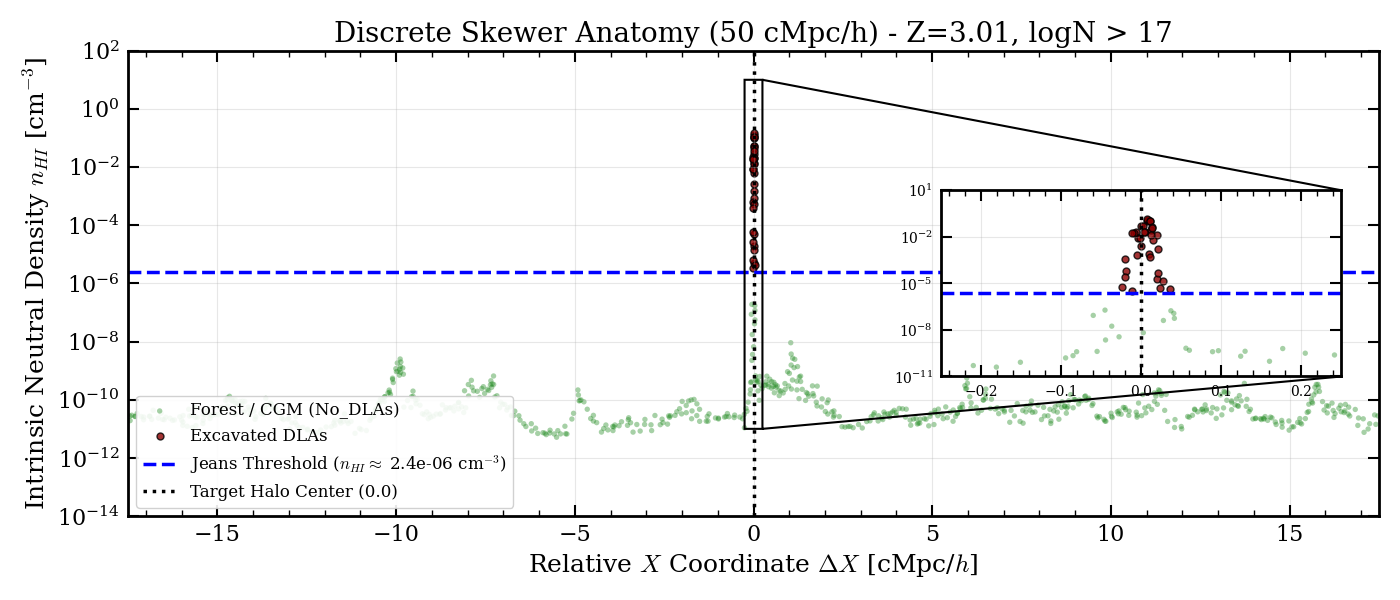

In [3]:
# ==============================================================================
# CELL 4: PLOT THE RAW DISCRETE DATA (FULL SKEWER - n_HI)
# ==============================================================================
# PLOT 1: DISCRETE ANATOMY
fig, ax = plt.subplots(figsize=(14, 6))

# Plot using relative coordinates centered on the halo (matching the other plots)
ax.scatter(dx_skewer_wrapped[mask_nodla], nHI_raw[mask_nodla], color='forestgreen', alpha=0.4, edgecolors='none', s=15, label='Forest / CGM (No_DLAs)')
ax.scatter(dx_skewer_wrapped[mask_dla], nHI_raw[mask_dla], color='darkred', alpha=0.8, edgecolors='black', s=25, label='Excavated DLAs')

# Theoretical and Geometric Markers
ax.axhline(dla_thresh_nHI, color='blue', linestyle='--', lw=2.5, label=rf'Jeans Threshold ($n_{{HI}} \approx$ {dla_thresh_nHI:.1e} cm$^{{-3}}$)')
ax.axvline(0.0, color='black', linestyle=':', lw=2.5, label='Target Halo Center (0.0)')

ax.set_yscale('log')
ax.set_ylim(1e-14, 1e2)
ax.set_xlim(-box_size_cMpc / 2.0, box_size_cMpc / 2.0) 

ax.set_xlabel(r'Relative $X$ Coordinate $\Delta X$ [cMpc/$h$]')
ax.set_ylabel(r'Intrinsic Neutral Density $n_{HI}$ [cm$^{-3}$]')
ax.set_title(f'Discrete Skewer Anatomy (50 cMpc/h) - Z={z_sim:.2f}, logN > {N_thresh}')

ax.legend(loc='lower left', framealpha=0.9, fontsize=12) 
ax.grid(True, alpha=0.3)

# ==============================================================================
# INSET: Zoom on the region of the Halo
# ==============================================================================

# Cria o eixo do inset (zoom)
# Parâmetros: [x, y, largura, altura] em coordenadas relativas do gráfico principal (0 a 1)
# Coloquei no canto superior direito para não cobrir os dados importantes
axins = ax.inset_axes([0.65, 0.3, 0.32, 0.40])

# 1. Re-plotar os dados no inset
axins.scatter(dx_skewer_wrapped[mask_nodla], nHI_raw[mask_nodla], 
              color='forestgreen', alpha=0.4, edgecolors='none', s=15)
axins.scatter(dx_skewer_wrapped[mask_dla], nHI_raw[mask_dla], 
              color='darkred', alpha=0.8, edgecolors='black', s=25)

# 2. Re-plotar as linhas de referência no inset
axins.axhline(dla_thresh_nHI, color='blue', linestyle='--', lw=2.5)
axins.axvline(0.0, color='black', linestyle=':', lw=2.5)

# 3. Definir os limites do zoom com base no retângulo desenhado
x1, x2 = -0.25, 0.25
y1, y2 = 1e-11, 1e1

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)
axins.set_yscale('log')

# Formatação extra para o inset
axins.grid(True, alpha=0.3)
axins.tick_params(labelsize=10)

# 4. Desenhar a caixa na região original e as linhas conectando ao zoom
ax.indicate_inset_zoom(axins, edgecolor="black", alpha=1.0, lw=1.5)

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# CELL 5: CONTINUOUS FUNCTION FITTING (FULL BOX WITH PBC)
# ==============================================================================
print("\nFitting a continuous function to the discrete n_HI data across the FULL box...")

# Create a fine grid for the entire box (50,000 bins)
num_bins = 50000
x_fine, step = np.linspace(-box_size_cMpc / 2.0, box_size_cMpc / 2.0, num_bins, retstep=True)

# Bin the discrete points in log-space across the whole wrapped box
log_nHI_binned, bin_edges, _ = binned_statistic(
    dx_skewer_wrapped, 
    np.log10(nHI_raw + 1e-30), 
    statistic='mean', 
    bins=num_bins, 
    range=(x_fine[0], x_fine[-1])
)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2.0

# Fill empty bins (NaNs) via linear interpolation
valid_mask = ~np.isnan(log_nHI_binned)
interp_log = interp1d(bin_centers[valid_mask], log_nHI_binned[valid_mask], kind='linear', fill_value="extrapolate")
filled_log_nHI = interp_log(bin_centers)

# Apply a Gaussian filter to smooth the data (mode='wrap' is CRITICAL for PBC)
smoothed_log_nHI = gaussian_filter1d(filled_log_nHI, sigma=5, mode='wrap')
f_nHI_continuous = 10**smoothed_log_nHI # Convert back to linear density

# Find the exact peak near the center
center_search_mask = (bin_centers > -1.0) & (bin_centers < 1.0)
peak_idx_local = np.argmax(f_nHI_continuous[center_search_mask])
x_peak = bin_centers[center_search_mask][peak_idx_local]
max_nHI = f_nHI_continuous[center_search_mask][peak_idx_local]

print(f"-> Target Peak found at relative coordinate X = {x_peak:.5f} cMpc/h with n_HI = {max_nHI:.2e} cm^-3")

# ==============================================================================
# CELL 6: INTEGRATING N_HI IN EXPANDING BINS AROUND THE PEAK
# ==============================================================================
cm_per_Mpc = 3.085678e24
conversion_factor_to_cm = (cm_per_Mpc / hubble) / (1.0 + z_sim)

nHI_func = interp1d(bin_centers, f_nHI_continuous, kind='cubic', fill_value=1e-30, bounds_error=False)

# Safely expand from 10^-5 up to the full box size
delta_x_array = np.logspace(-5, np.log10(box_size_cMpc - 0.1), 1000) 

N_HI_list = []
valid_delta_x = []

print("\nIntegrating N_HI expanding outwards from the peak...")
for dx in delta_x_array:
    x_min = x_peak - (dx / 2.0)
    x_max = x_peak + (dx / 2.0)
    
    # Subgrid proportional to dx, capped to avoid memory exhaustion
    subgrid_size = max(100, min(10000, int((dx / step) * 2)))
    subgrid = np.linspace(x_min, x_max, subgrid_size)
    y_vals = nHI_func(subgrid)
    
    integral_cMpc_h = np.trapz(y_vals, subgrid)
    N_HI_val = integral_cMpc_h * conversion_factor_to_cm
    
    N_HI_list.append(N_HI_val)
    valid_delta_x.append(dx)

valid_delta_x = np.array(valid_delta_x)
N_HI_list = np.array(N_HI_list)

# ==============================================================================
# CELL 7: DERIVING EMPIRICAL n_lim USING ASYMPTOTE INTERSECTION
# ==============================================================================
print("\nDeriving empirical density threshold via Asymptote Intersection...")

log_dx = np.log10(valid_delta_x)
log_NHI = np.log10(N_HI_list)

# 1. Plateau Asymptote (Y_max)
Y_max = np.mean(log_NHI[-50:])

# 2. Growth Asymptote (Tangent line at maximum slope)
smooth_log_NHI = gaussian_filter1d(log_NHI, sigma=2)
dy_dx = np.gradient(smooth_log_NHI, log_dx)

idx_max_slope = np.argmax(dy_dx)
m_growth = dy_dx[idx_max_slope]
x_growth = log_dx[idx_max_slope]
y_growth = smooth_log_NHI[idx_max_slope]

# 3. Intersection Point (The Morphological 'Knee')
X_trans = x_growth + (Y_max - y_growth) / m_growth
dx_trans = 10**X_trans
NHI_trans = 10**Y_max

print(f"-> Asymptote Intersection (Knee) found at delta_x = {dx_trans:.5e} cMpc/h")
print(f"-> Saturation N_HI (Plateau) = {NHI_trans:.3e} cm^-2")

# 4. Extract Empirical physical boundaries and threshold (n_lim)
x_left = x_peak - (dx_trans / 2.0)
x_right = x_peak + (dx_trans / 2.0)

n_lim_left = float(nHI_func(x_left))
n_lim_right = float(nHI_func(x_right))

# Average to account for profile asymmetries
n_lim_derived = (n_lim_left + n_lim_right) / 2.0

print(f"-> Evaluated n_HI at left boundary  (x={x_left:.4f}): {n_lim_left:.3e} cm^-3")
print(f"-> Evaluated n_HI at right boundary (x={x_right:.4f}): {n_lim_right:.3e} cm^-3")
print(f"-> NEW Empirical Threshold (n_lim): {n_lim_derived:.3e} cm^-3")


Fitting a continuous function to the discrete n_HI data across the FULL box...
-> Target Peak found at relative coordinate X = 0.00875 cMpc/h with n_HI = 2.13e-02 cm^-3

Integrating N_HI expanding outwards from the peak...

Deriving empirical density threshold via Asymptote Intersection...
-> Asymptote Intersection (Knee) found at delta_x = 1.06331e-02 cMpc/h
-> Saturation N_HI (Plateau) = 2.573e+20 cm^-2
-> Evaluated n_HI at left boundary  (x=0.0034): 6.015e-03 cm^-3
-> Evaluated n_HI at right boundary (x=0.0141): 6.132e-03 cm^-3
-> NEW Empirical Threshold (n_lim): 6.073e-03 cm^-3


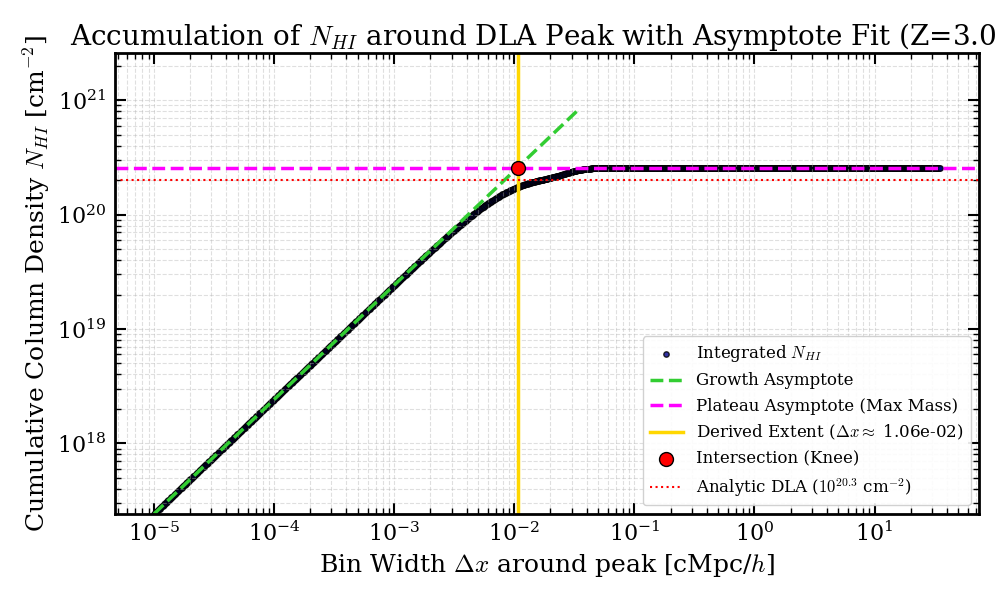

In [5]:
# ==============================================================================
# CELL 8: PLOT ACCUMULATION CURVE & ASYMPTOTES
# ==============================================================================
# PLOT 2: ASYMPTOTES
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(valid_delta_x, N_HI_list, color='darkblue', s=15, alpha=0.8, edgecolor='black', label='Integrated $N_{HI}$')

# Plot the Growth Asymptote
x_line = np.linspace(log_dx[0], X_trans + 0.5, 100)
y_line = m_growth * (x_line - x_growth) + y_growth
ax.plot(10**x_line, 10**y_line, color='limegreen', lw=2.5, linestyle='--', label='Growth Asymptote')

# Plot the Plateau Asymptote
ax.axhline(NHI_trans, color='magenta', lw=2.5, linestyle='--', label='Plateau Asymptote (Max Mass)')

# Highlight the Intersection
ax.axvline(dx_trans, color='gold', linestyle='-', lw=2.5, label=rf'Derived Extent ($\Delta x \approx$ {dx_trans:.2e})')
ax.scatter([dx_trans], [NHI_trans], color='red', s=100, zorder=10, edgecolors='black', label='Intersection (Knee)')

# Analytic threshold for reference
ax.axhline(10**20.3, color='red', linestyle=':', lw=1.5, label=r'Analytic DLA ($10^{20.3}$ cm$^{-2}$)')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(bottom=10**(y_line[0]), top=NHI_trans * 10)

ax.set_xlabel(r'Bin Width $\Delta x$ around peak [cMpc/$h$]')
ax.set_ylabel(r'Cumulative Column Density $N_{HI}$ [cm$^{-2}$]')
ax.set_title(f'Accumulation of $N_{{HI}}$ around DLA Peak with Asymptote Fit (Z={z_sim:.2f})')

ax.grid(True, alpha=0.4, which='both', linestyle='--')
ax.legend(loc='lower right', framealpha=0.9, fontsize=12)

plt.tight_layout()
plt.show()



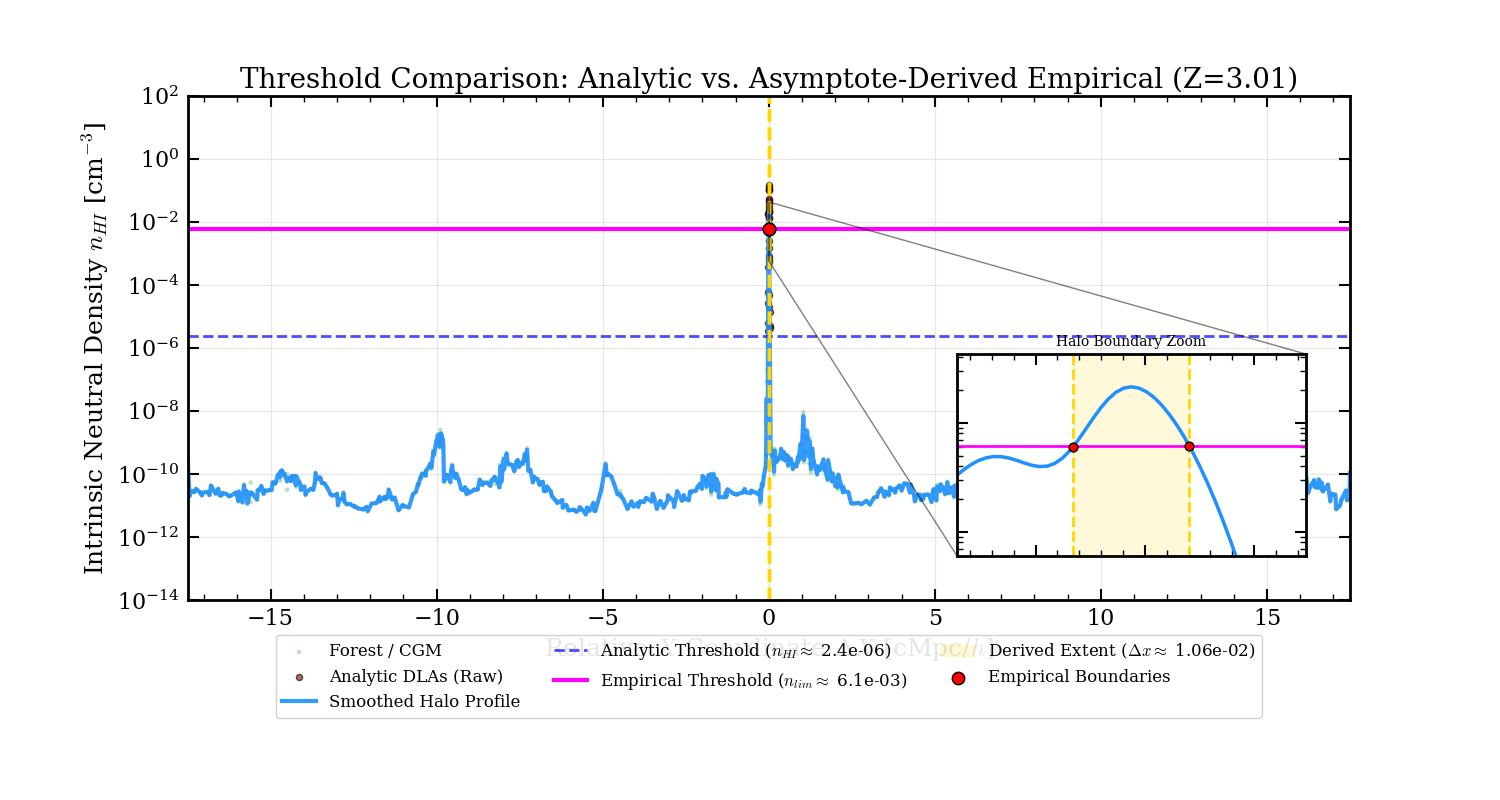

In [6]:
# ==============================================================================
# CELL 9: PLOT FULL SKEWER COMPARING ANALYTIC VS EMPIRICAL THRESHOLDS
# ==============================================================================
# PLOT 3: FULL OVERLAY WITH INSET
fig, ax = plt.subplots(figsize=(15, 8))

# Plot all raw discrete data across the entire box (Using Wrapped coordinates)
ax.scatter(dx_skewer_wrapped[mask_nodla], nHI_raw[mask_nodla], color='forestgreen', alpha=0.3, edgecolors='none', s=10, label='Forest / CGM')
ax.scatter(dx_skewer_wrapped[mask_dla], nHI_raw[mask_dla], color='darkred', alpha=0.6, edgecolors='black', s=20, label='Analytic DLAs (Raw)')

# Plot the continuous smoothed function
ax.plot(bin_centers, f_nHI_continuous, color='dodgerblue', lw=3.0, alpha=0.9, label='Smoothed Halo Profile')

# Plot the thresholds
ax.axhline(dla_thresh_nHI, color='blue', linestyle='--', lw=2.0, alpha=0.7,
           label=rf'Analytic Threshold ($n_{{HI}} \approx$ {dla_thresh_nHI:.1e})')

# Empirical (Derived from Asymptotes)
ax.axhline(n_lim_derived, color='magenta', linestyle='-', lw=3.0, 
           label=rf'Empirical Threshold ($n_{{lim}} \approx$ {n_lim_derived:.1e})')

# Highlight the derived physical boundaries
ax.axvline(x_left, color='gold', linestyle='--', lw=2.5)
ax.axvline(x_right, color='gold', linestyle='--', lw=2.5)
ax.axvspan(x_left, x_right, color='gold', alpha=0.15, label=rf'Derived Extent ($\Delta x \approx$ {dx_trans:.2e})')

# Boundary Points
ax.scatter([x_left, x_right], [n_lim_left, n_lim_right], color='red', s=80, zorder=5, edgecolors='black', label='Empirical Boundaries')

ax.set_yscale('log')
ax.set_ylim(1e-14, 1e2)
ax.set_xlim(-box_size_cMpc / 2.0, box_size_cMpc / 2.0)

# ------------------------------------------------------------------------------
# INSET: Zoom on the Halo Profile Edge
# ------------------------------------------------------------------------------
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
axins = inset_axes(ax, width="30%", height="40%", loc='lower right', borderpad=2)
axins.plot(bin_centers, f_nHI_continuous, color='dodgerblue', lw=2.5)
axins.axhline(dla_thresh_nHI, color='blue', linestyle='--', lw=1.5, alpha=0.7)
axins.axhline(n_lim_derived, color='magenta', linestyle='-', lw=2)
axins.axvline(x_left, color='gold', linestyle='--', lw=2)
axins.axvline(x_right, color='gold', linestyle='--', lw=2)
axins.axvspan(x_left, x_right, color='gold', alpha=0.15)
axins.scatter([x_left, x_right], [n_lim_left, n_lim_right], color='red', s=40, zorder=5, edgecolors='black')
axins.set_yscale('log')

# Dynamically set zoom limits around the transition bounds
axins.set_xlim(x_peak - dx_trans*1.5, x_peak + dx_trans*1.5)
axins.set_ylim(n_lim_derived / 10, np.max(f_nHI_continuous) * 2)
axins.set_title("Halo Boundary Zoom", fontsize=10)
axins.tick_params(labelleft=False, labelbottom=False)
ax.indicate_inset_zoom(axins, edgecolor="black")

ax.set_xlabel(r'Relative $X$ Coordinate $\Delta X$ [cMpc/$h$]')
ax.set_ylabel(r'Intrinsic Neutral Density $n_{HI}$ [cm$^{-3}$]')
ax.set_title(rf'Threshold Comparison: Analytic vs. Asymptote-Derived Empirical (Z={z_sim:.2f})')

ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=3, framealpha=0.9, fontsize=12)
ax.grid(True, alpha=0.3)

plt.subplots_adjust(bottom=0.25)
plt.show()